# 01. Exploring the Criteo uplift data

**The question this notebook answers:** before we test anything, what is actually in this
experiment file? How rare are the outcomes we care about, and do the users who were shown the
campaign look like the users who were held back?

The file has about 14 million rows, so nothing here loads it into pandas. Every table and chart
below comes from a **DuckDB aggregate query** (the SQL is in the cells and in `sql/`), so the
numbers are exact, not a sample.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from expkit import data, nb
from expkit.report import pct

ctx = nb.load()
con, R, FEATURES = ctx.con, ctx.results, data.FEATURES
ctx.banner()

> Data: **Criteo Uplift v2.1**. Pipeline numbers are read from `docs/results/results.json` (written by `expkit run-all` at code commit `41db89a`) and match `docs/RESULTS.md`. Seed 42.

## 1. Data shape and data dictionary

In [2]:
n_rows = con.execute("SELECT count(*) FROM criteo").fetchone()[0]
cols = con.execute("DESCRIBE criteo").df()[["column_name", "column_type"]]
nb.md(
    f"The `criteo` table has **{n_rows:,} rows** and **{len(cols)} columns** "
    f"(the 12 features, 4 outcome and assignment columns, and a `row_id` that our SQL adds so "
    f"the train, validation and test split is reproducible)."
)

dictionary = pd.DataFrame(
    [
        (
            "row_id",
            "added by `sql/01_criteo_load.sql`",
            "Position of the row in the file. Used only to build the split.",
        ),
        (
            "f0 to f11",
            "12 numeric features",
            "Anonymized user attributes. Their meaning is not published.",
        ),
        (
            "treatment",
            "0 or 1",
            "1 if the user was randomly assigned to the ad campaign, 0 if held back (control).",
        ),
        (
            "visit",
            "0 or 1",
            "1 if the user visited the advertiser's site during the observation window. Main outcome.",
        ),
        ("conversion", "0 or 1", "1 if the user bought something. Much rarer than a visit."),
        (
            "exposure",
            "0 or 1",
            "1 if the user actually saw the ad. Happens after assignment, so it is never used as a model input.",
        ),
    ],
    columns=["column", "type", "meaning (from the dataset documentation)"],
).set_index("column")
display(dictionary)

The `criteo` table has **13,979,592 rows** and **17 columns** (the 12 features, 4 outcome and assignment columns, and a `row_id` that our SQL adds so the train, validation and test split is reproducible).

,type,meaning (from the dataset documentation)
column,,
row_id,added by `sql/01_criteo_load.sql`,Position of the row in the file. Used only to ...
f0 to f11,12 numeric features,Anonymized user attributes. Their meaning is n...
treatment,0 or 1,1 if the user was randomly assigned to the ad ...
visit,0 or 1,1 if the user visited the advertiser's site du...
conversion,0 or 1,1 if the user bought something. Much rarer tha...
exposure,0 or 1,1 if the user actually saw the ad. Happens aft...


The twelve features, summarized exactly in one SQL pass. "Distinct values" tells us which
features behave like categories (few values) and which are close to continuous.

In [3]:
parts = []
for f in FEATURES:
    parts.append(
        f"approx_count_distinct({f}) AS {f}_distinct, min({f}) AS {f}_min, "
        f"approx_quantile({f}, 0.5) AS {f}_median, approx_quantile({f}, 0.99) AS {f}_p99, "
        f"max({f}) AS {f}_max, avg({f}) AS {f}_mean, stddev_samp({f}) AS {f}_sd"
    )
row = con.execute("SELECT " + ", ".join(parts) + " FROM criteo").df().iloc[0]
summary = pd.DataFrame(
    {
        "distinct values (approx.)": [int(row[f"{f}_distinct"]) for f in FEATURES],
        "min": [row[f"{f}_min"] for f in FEATURES],
        "median": [row[f"{f}_median"] for f in FEATURES],
        "mean": [row[f"{f}_mean"] for f in FEATURES],
        "std dev": [row[f"{f}_sd"] for f in FEATURES],
        "99th pct": [row[f"{f}_p99"] for f in FEATURES],
        "max": [row[f"{f}_max"] for f in FEATURES],
    },
    index=pd.Index(FEATURES, name="feature"),
)
display(summary.round(3))
discrete = [f for f in FEATURES if row[f"{f}_distinct"] <= 70]
nb.md(
    f"Features with 70 or fewer distinct values (they behave like categories): "
    f"{', '.join(discrete) if discrete else 'none'}. The other {12 - len(discrete)} take many values, "
    f"but most of them have one very common value (see the next sections), so a typical user "
    f"sits on the same spot for several features."
)

,distinct values (approx.),min,median,mean,std dev,99th pct,max
feature,,,,,,,
f0,2159945,12.616,21.918,19.620,5.377,26.666,26.745
f1,61,10.060,10.060,10.070,0.105,10.627,16.344
f2,847549,8.214,8.214,8.447,0.299,9.043,9.052
f3,553,-8.398,4.680,4.179,1.337,4.680,4.680
f4,264,10.281,10.281,10.339,0.343,11.967,21.124
f5,130,-9.012,4.115,4.029,0.431,4.115,4.115
f6,1640,-31.430,-2.449,-4.155,4.578,0.294,0.294
f7,627176,4.834,4.834,5.102,1.205,11.467,11.998
f8,3787,3.635,3.972,3.934,0.057,3.972,3.972


Features with 70 or fewer distinct values (they behave like categories): f1. The other 11 take many values, but most of them have one very common value (see the next sections), so a typical user sits on the same spot for several features.

## 2. Missing values and basic logic checks

In [4]:
null_sql = ", ".join(
    f"count(*) - count({c}) AS {c}_null, count(*) FILTER (WHERE isnan({c})) AS {c}_nan"
    for c in FEATURES
)
nulls = con.execute(f"SELECT {null_sql} FROM criteo").df().iloc[0]
outcome_nulls = (
    con.execute(
        "SELECT "
        + ", ".join(
            f"count(*) - count({c}) AS {c}"
            for c in ["treatment", "visit", "conversion", "exposure"]
        )
        + " FROM criteo"
    )
    .df()
    .iloc[0]
)
missing_total = int(nulls.sum() + outcome_nulls.sum())

checks = (
    con.execute(
        """
    SELECT
        count(*) FILTER (WHERE conversion = 1 AND visit = 0) AS conversions_without_visit,
        count(*) FILTER (WHERE exposure = 1 AND treatment = 0) AS exposed_in_control,
        count(*) FILTER (WHERE exposure = 1 AND visit = 0) AS exposed_without_visit,
        count(*) FILTER (WHERE exposure = 1) AS exposed_total
    FROM criteo
    """
    )
    .df()
    .iloc[0]
)
nb.md(
    f"- Missing or NaN cells across all columns: **{missing_total:,}**.\n"
    f"- Users with a conversion but no visit: **{int(checks.conversions_without_visit):,}**.\n"
    f"- Control users recorded as exposed to the ad: **{int(checks.exposed_in_control):,}** "
    f"(must be 0, since control users are held back).\n"
    f"- Exposed users who did not visit: **{int(checks.exposed_without_visit):,}** of "
    f"{int(checks.exposed_total):,} exposed users."
)

- Missing or NaN cells across all columns: **0**.
- Users with a conversion but no visit: **0**.
- Control users recorded as exposed to the ad: **0** (must be 0, since control users are held back).
- Exposed users who did not visit: **250,702** of 428,212 exposed users.

## 3. Outcome rates and class imbalance

The three rates below are shown by arm. Note the very different scales: a visit is rare, a
purchase is much rarer, and only a small share of treated users actually saw the ad.

- Check: control users: recomputed `2.09694e+06`, pipeline `2.09694e+06` (matches)

- Check: control visits: recomputed `80105`, pipeline `80105` (matches)

- Check: treatment users: recomputed `1.18827e+07`, pipeline `1.18827e+07` (matches)

- Check: treatment visits: recomputed `576824`, pipeline `576824` (matches)

,users,visit rate,conversion rate,exposure rate
control,2096937,3.820%,0.194%,0.000%
treated,11882655,4.854%,0.309%,3.604%


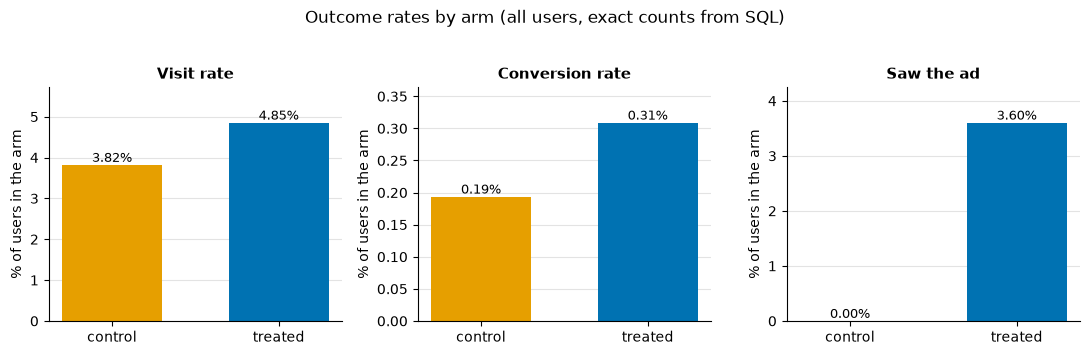

In [5]:
arms = data.run_sql(con, "03_arm_summary.sql").set_index("treatment")
for arm_id, key in ((0, "control"), (1, "treatment")):
    ctx.check(f"{key} users", float(arms.loc[arm_id, "n"]), float(R["design"]["arms"][key]["n"]))
    ctx.check(
        f"{key} visits",
        float(arms.loc[arm_id, "visits"]),
        float(R["design"]["arms"][key]["visits"]),
    )

rates = pd.DataFrame(
    {
        "users": arms["n"],
        "visit rate": arms["visits"] / arms["n"],
        "conversion rate": arms["conversions"] / arms["n"],
        "exposure rate": arms["exposed"] / arms["n"],
    }
)
rates.index = ["control", "treated"]
display(rates.assign(**{c: rates[c].map(lambda v: f"{v:.3%}") for c in rates.columns[1:]}))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (col, title) in zip(
    axes,
    [
        ("visit rate", "Visit rate"),
        ("conversion rate", "Conversion rate"),
        ("exposure rate", "Saw the ad"),
    ],
):
    vals = rates[col].to_numpy() * 100
    bars = ax.bar(["control", "treated"], vals, color=[nb.CONTROL, nb.TREATED], width=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}%", ha="center", va="bottom", fontsize=9)
    ax.set_title(title)
    ax.set_ylabel("% of users in the arm")
    ax.set_ylim(0, max(vals) * 1.18 if max(vals) > 0 else 1)
    ax.grid(axis="x", visible=False)
fig.suptitle("Outcome rates by arm (all users, exact counts from SQL)", y=1.03, fontsize=12)
fig.tight_layout()
ctx.savefig(fig, "eda_outcome_rates")

In [6]:
n_all = int(arms["n"].sum())
visit_rate = float(arms["visits"].sum() / n_all)
conv_rate = float(arms["conversions"].sum() / n_all)
nb.md(
    f"**Class imbalance.** Only {pct(visit_rate)} of users visit (1 in {1 / visit_rate:,.0f}) and "
    f"{pct(conv_rate, 3)} convert (1 in {1 / conv_rate:,.0f}). A model that always predicts "
    f'"no visit" would be {pct(1 - visit_rate)} accurate, so accuracy is useless here. The '
    f"toolkit judges models by ranking quality (Qini curves, AUC) instead. There are "
    f"{int(arms['visits'].sum()):,} visits to learn from but only {int(arms['conversions'].sum()):,} "
    f"conversions, which is why visit, not conversion, is the outcome we model."
)

**Class imbalance.** Only 4.70% of users visit (1 in 21) and 0.292% convert (1 in 343). A model that always predicts "no visit" would be 95.30% accurate, so accuracy is useless here. The toolkit judges models by ranking quality (Qini curves, AUC) instead. There are 656,929 visits to learn from but only 40,774 conversions, which is why visit, not conversion, is the outcome we model.

## 4. Feature distributions by arm

Exact counts from SQL. Features with few distinct values are counted by value. The others are
cut into 50 equal-width bins between the 0.1th and 99.9th percentiles (values outside are
folded into the end bins). Each line is the **share of that arm's users**, so the 85% / 15%
size difference does not distort the comparison. The y axis is logarithmic because most
features have one very common value that would otherwise flatten everything else.

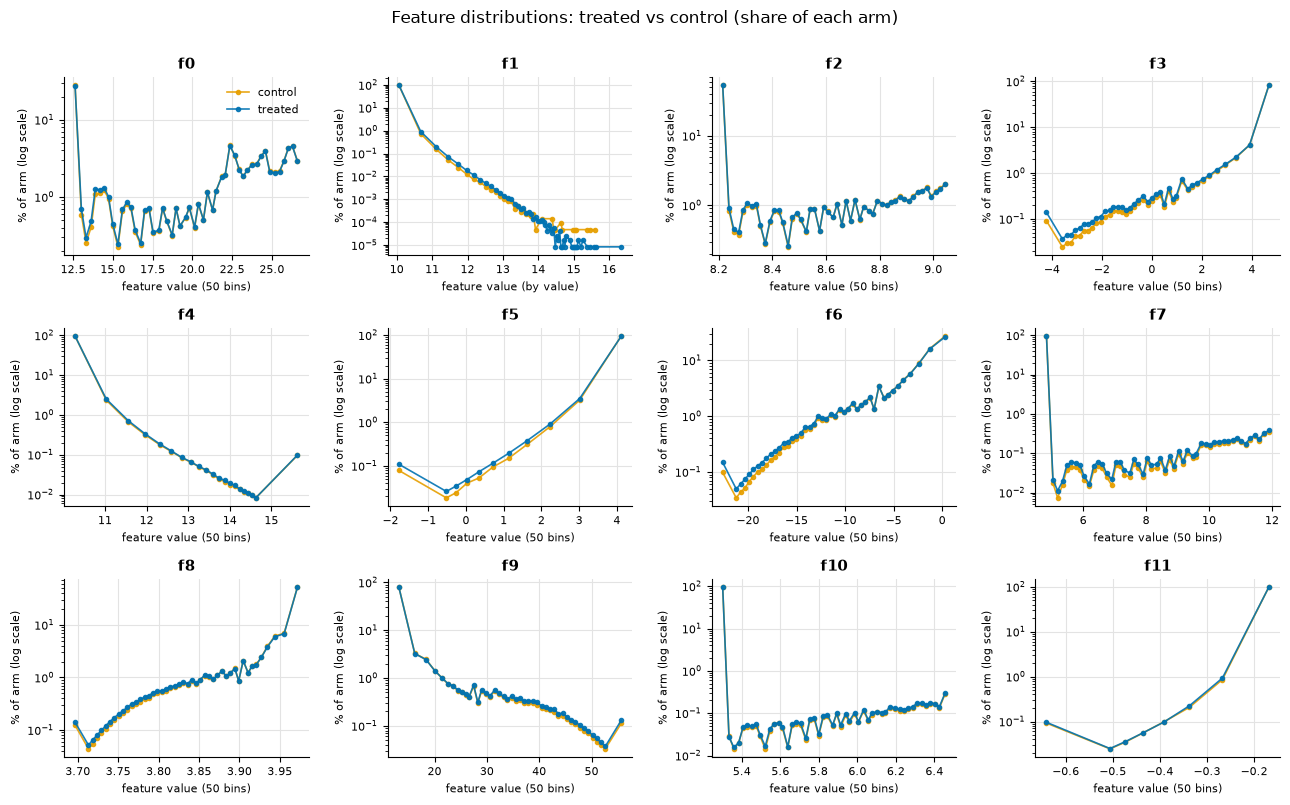

The treated and control lines nearly coincide for every feature, as random assignment should produce. For 10 of the 12 features more than half of all users fall in a single bin (f1, f2, f3, f4, f5, f7, f8, f9, f10, f11), so those features mostly separate a large common group from a thin tail. The thin tails are where small gaps show up: the largest treated-to-control ratios of tail share are f1 (1.27), f5 (1.21), f3 (1.15) (1.00 would be identical). The next chart puts a number on the whole-distribution gap.

In [7]:
N_FINE = 50


def fine_bins(f: str) -> pd.DataFrame:
    """One row per value (few-valued features) or per equal-width bin, with counts by arm."""
    agg = (
        f"avg({f}::DOUBLE) AS x, count(*) FILTER (WHERE treatment = 0)::BIGINT AS n0, "
        "count(*) FILTER (WHERE treatment = 1)::BIGINT AS n1, "
        "coalesce(sum(visit) FILTER (WHERE treatment = 0), 0)::BIGINT AS v0, "
        "coalesce(sum(visit) FILTER (WHERE treatment = 1), 0)::BIGINT AS v1"
    )
    if row[f"{f}_distinct"] <= 70:
        q = f"SELECT {f}::DOUBLE AS b, {agg} FROM criteo GROUP BY 1 ORDER BY 1"
    else:
        lo, hi = con.execute(
            f"SELECT approx_quantile({f}, 0.001), approx_quantile({f}, 0.999) FROM criteo"
        ).fetchone()
        width = (float(hi) - float(lo)) / N_FINE
        L, W = f"({float(lo)!r}::DOUBLE)", f"({width!r}::DOUBLE)"
        b = f"least({N_FINE - 1}, greatest(0, floor(({f}::DOUBLE - {L}) / {W})::INT))"
        q = f"SELECT {b} AS b, {agg} FROM criteo GROUP BY 1 ORDER BY 1"
    return con.execute(q).df()


fine = {f: fine_bins(f) for f in FEATURES}
arm_n = arms["n"].to_dict()

fig, axes = plt.subplots(3, 4, figsize=(13, 8))
for ax, f in zip(axes.ravel(), FEATURES):
    d = fine[f]
    for arm_id, color, label in ((0, nb.CONTROL, "control"), (1, nb.TREATED, "treated")):
        share = d[f"n{arm_id}"] / arm_n[arm_id] * 100
        keep = share > 0
        ax.plot(
            d.loc[keep, "x"], share[keep], "-o", color=color, ms=3, lw=1.2, label=label, alpha=0.9
        )
    ax.set_yscale("log")
    ax.set_title(f)
    ax.set_xlabel("feature value" + (" (by value)" if f in discrete else " (50 bins)"), fontsize=8)
    ax.set_ylabel("% of arm (log scale)", fontsize=8)
    ax.tick_params(labelsize=8)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Feature distributions: treated vs control (share of each arm)", y=1.0, fontsize=12)
fig.tight_layout()
ctx.savefig(fig, "eda_feature_distributions")

modal = {f: float(max(fine[f]["n0"] + fine[f]["n1"]) / n_all) for f in FEATURES}
heavy = [f for f in FEATURES if modal[f] > 0.5]

# How much more (or less) of the treated arm than of the control arm sits in each feature's rare
# bins (bins holding under 1% of all users)? A ratio of 1 means identical tails.
tail_ratio = {}
for f in FEATURES:
    d = fine[f]
    rare = (d["n0"] + d["n1"]) < 0.01 * n_all
    if rare.any():
        tail_ratio[f] = float(
            (d.loc[rare, "n1"].sum() / arm_n[1]) / (d.loc[rare, "n0"].sum() / arm_n[0])
        )
largest_tail = sorted(tail_ratio.items(), key=lambda kv: abs(np.log(kv[1])), reverse=True)[:3]
nb.md(
    f"The treated and control lines nearly coincide for every feature, as random assignment "
    f"should produce. For {len(heavy)} of the 12 features more than half of all users fall in a "
    f"single bin ({', '.join(heavy) if heavy else 'none'}), so those features mostly separate a "
    f"large common group from a thin tail. The thin tails are where small gaps show up: the "
    f"largest treated-to-control ratios of tail share are "
    + ", ".join(f"{f} ({r:.2f})" for f, r in largest_tail)
    + " (1.00 would be identical). The next chart puts a number on the whole-distribution gap."
)

## 5. Treated vs control balance (standardized mean differences)

The standardized mean difference (SMD) is the gap between the arm means divided by the pooled
standard deviation. A common rule of thumb calls anything under 0.1 well balanced.

- Check: largest absolute SMD: recomputed `0.0488363`, pipeline `0.0488363` (matches)

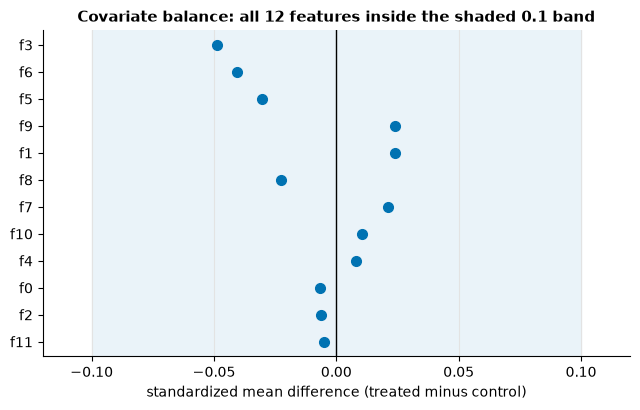

The largest absolute SMD is **0.049** (f3). Every feature is inside the 0.1 rule of thumb. A one-feature-at-a-time check like this can miss small differences that add up across several features, so notebook 02 also asks whether a model can predict assignment.

In [8]:
bal = data.run_sql(con, "04_feature_balance.sql").set_index("treatment")
smd = np.array(
    [
        (bal.loc[1, f"m{i}"] - bal.loc[0, f"m{i}"])
        / np.sqrt((bal.loc[0, f"s{i}"] ** 2 + bal.loc[1, f"s{i}"] ** 2) / 2)
        for i in range(12)
    ]
)
ctx.check("largest absolute SMD", float(np.abs(smd).max()), R["design"]["max_abs_smd"], rtol=1e-9)

order = np.argsort(np.abs(smd))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.axvspan(-0.1, 0.1, color="#EAF3F9", zorder=0)
ax.axvline(0, color=nb.BLACK, lw=1)
ax.plot(smd[order], range(12), "o", color=nb.BLUE, ms=7)
ax.set_yticks(range(12))
ax.set_yticklabels([FEATURES[i] for i in order])
ax.set_xlim(-0.12, 0.12)
ax.set_xlabel("standardized mean difference (treated minus control)")
ax.set_title("Covariate balance: all 12 features inside the shaded 0.1 band")
ax.grid(axis="y", visible=False)
fig.tight_layout()
ctx.savefig(fig, "eda_smd")

within = bool(np.all(np.abs(smd) < 0.1))
nb.md(
    f"The largest absolute SMD is **{np.abs(smd).max():.3f}** ({FEATURES[int(np.argmax(np.abs(smd)))]}). "
    + (
        "Every feature is inside the 0.1 rule of thumb. "
        if within
        else "Some features are outside the 0.1 rule of thumb. "
    )
    + "A one-feature-at-a-time check like this can miss small differences that add up across "
    "several features, so notebook 02 also asks whether a model can predict assignment."
)

## 6. Visit rate by feature group

Neighbouring bins from the previous section are merged until each group holds at least 0.5% of
all users, so every point rests on thousands of control users. Lines show the visit rate in
each group with 95% intervals. The gap between the blue and orange lines is the raw campaign
lift in that group. A feature with one dominant value ends up with only a few groups.

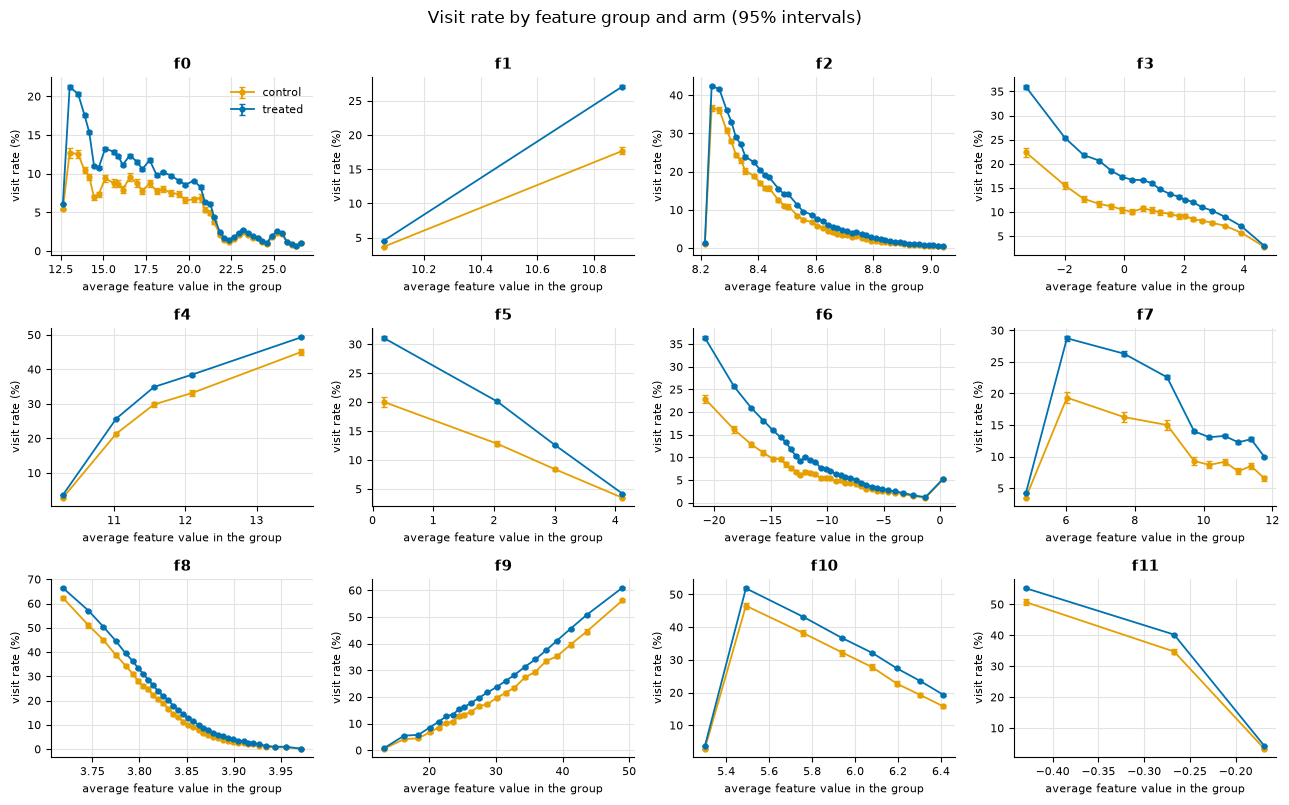

In [9]:
def merge_bins(d: pd.DataFrame, min_share: float = 0.005) -> pd.DataFrame:
    groups, cur = [], None
    for r in d.itertuples():
        if cur is None:
            cur = {"w": 0.0, "xw": 0.0, "n0": 0, "n1": 0, "v0": 0, "v1": 0}
        n = r.n0 + r.n1
        cur["w"] += n
        cur["xw"] += r.x * n
        for k in ("n0", "n1", "v0", "v1"):
            cur[k] += getattr(r, k)
        if cur["w"] >= min_share * n_all:
            groups.append(cur)
            cur = None
    if cur is not None and cur["w"] > 0:
        if groups:
            for k in cur:
                groups[-1][k] += cur[k]
        else:
            groups.append(cur)
    out = pd.DataFrame(groups)
    out["x"] = out["xw"] / out["w"]
    return out


bins = {f: merge_bins(fine[f]) for f in FEATURES}

fig, axes = plt.subplots(3, 4, figsize=(13, 8))
for ax, f in zip(axes.ravel(), FEATURES):
    b = bins[f]
    for arm_id, color, label in ((0, nb.CONTROL, "control"), (1, nb.TREATED, "treated")):
        p, hw = nb.rate_ci(b[f"v{arm_id}"].to_numpy(float), b[f"n{arm_id}"].to_numpy(float))
        ax.errorbar(
            b["x"],
            p * 100,
            yerr=hw * 100,
            fmt="-o",
            color=color,
            ms=3.5,
            lw=1.3,
            capsize=2,
            label=label,
        )
    ax.set_title(f)
    ax.set_xlabel("average feature value in the group", fontsize=8)
    ax.set_ylabel("visit rate (%)", fontsize=8)
    ax.tick_params(labelsize=8)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Visit rate by feature group and arm (95% intervals)", y=1.0, fontsize=12)
fig.tight_layout()
ctx.savefig(fig, "eda_visit_rate_by_feature")

The same groups, now showing the **difference** between treated and control. If the campaign
worked equally well for everybody, each panel would be a flat line. Slopes mean the effect
differs across users, which is the reason an uplift model can be worth building.

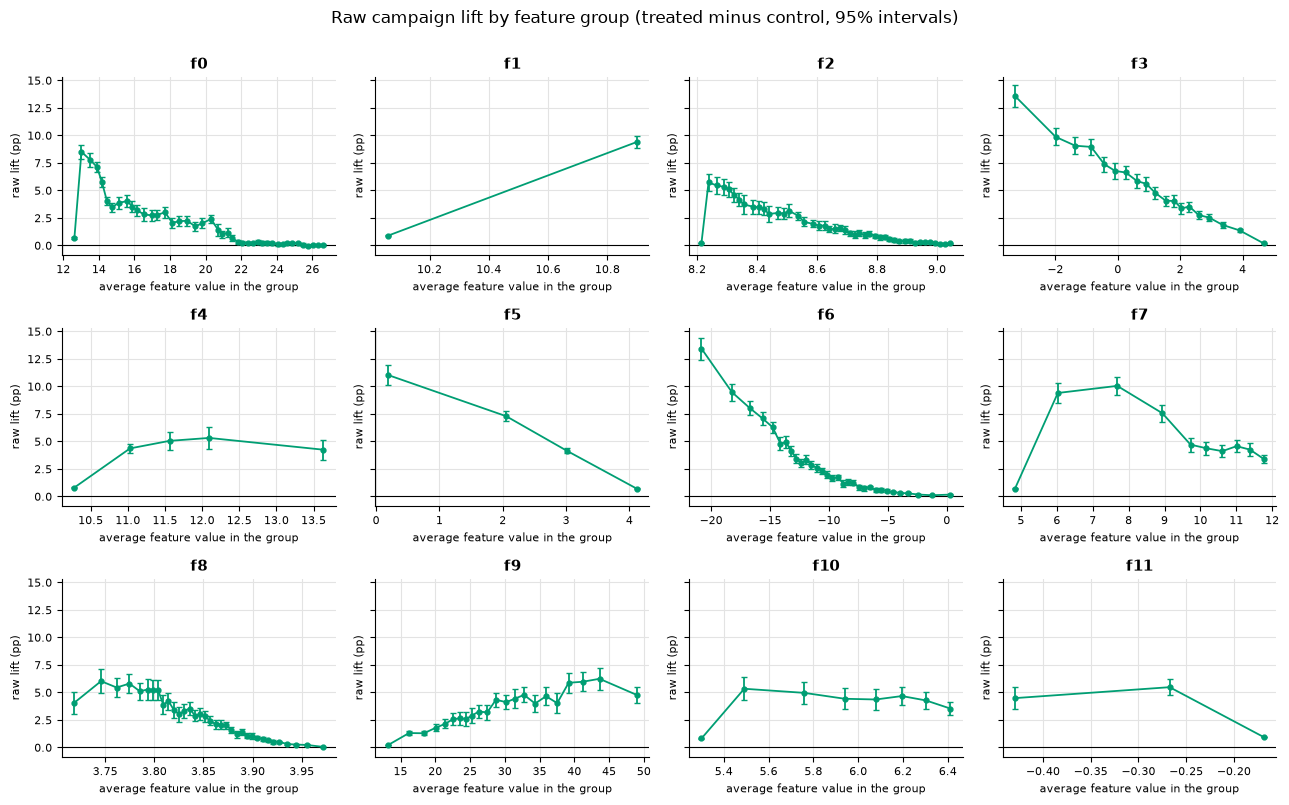

The feature with the widest spread of raw lift across its groups is **f3**: from +0.18 to +13.58 percentage points. This is raw lift, so it also carries the small arm imbalance discussed in notebook 02.

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(13, 8), sharey=True)
spread = []
for ax, f in zip(axes.ravel(), FEATURES):
    b = bins[f]
    pc, pt = b["v0"] / b["n0"], b["v1"] / b["n1"]
    se = np.sqrt(pc * (1 - pc) / b["n0"] + pt * (1 - pt) / b["n1"])
    lift = (pt - pc) * 100
    spread.append((f, float(lift.min()), float(lift.max())))
    ax.errorbar(
        b["x"], lift, yerr=1.96 * se * 100, fmt="-o", color=nb.GREEN, ms=3.5, lw=1.3, capsize=2
    )
    ax.axhline(0, color=nb.BLACK, lw=0.8)
    ax.set_title(f)
    ax.set_xlabel("average feature value in the group", fontsize=8)
    ax.set_ylabel("raw lift (pp)", fontsize=8)
    ax.tick_params(labelsize=8)
fig.suptitle(
    "Raw campaign lift by feature group (treated minus control, 95% intervals)", y=1.0, fontsize=12
)
fig.tight_layout()
ctx.savefig(fig, "eda_lift_by_feature")
widest = max(spread, key=lambda s: s[2] - s[1])
nb.md(
    f"The feature with the widest spread of raw lift across its groups is **{widest[0]}**: from "
    f"{widest[1]:+.2f} to {widest[2]:+.2f} percentage points. This is raw lift, so it also carries "
    f"the small arm imbalance discussed in notebook 02."
)

## 7. Correlation heatmap

Pearson correlations between the features and with the outcomes, computed exactly in SQL with
`corr()`. `exposure` is included only to show how it relates to the outcomes. It is measured
after assignment, so it is **not** a feature.

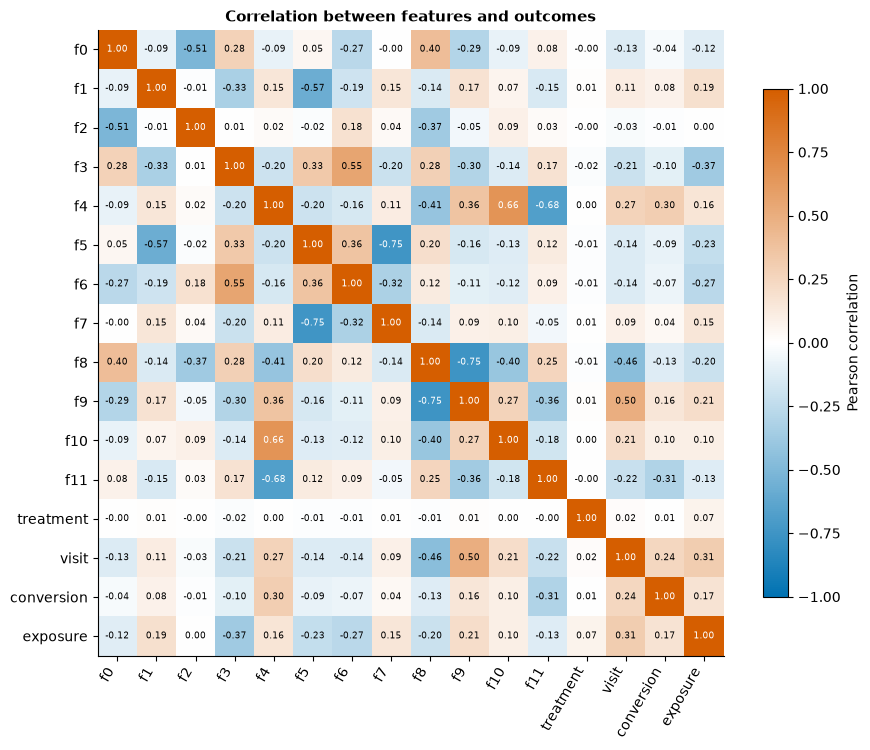

- Strongest feature-to-feature correlations: f8/f9 (-0.75), f5/f7 (-0.75), f4/f11 (-0.68). 7 of the 66 feature pairs have |correlation| above 0.5.
- Features most correlated with a visit: **f9** (+0.50), **f8** (-0.46), **f4** (+0.27). The features carry real signal about who visits.
- Correlation of `treatment` with any feature: at most 0.017, as expected from random assignment.

In [11]:
names = FEATURES + ["treatment", "visit", "conversion", "exposure"]
pairs = [(a, b) for i, a in enumerate(names) for b in names[i + 1 :]]
sql = ", ".join(f"corr({a}, {b}) AS c{k}" for k, (a, b) in enumerate(pairs))
vals = con.execute(f"SELECT {sql} FROM criteo").df().iloc[0].to_numpy()
corr = pd.DataFrame(np.eye(len(names)), index=names, columns=names)
for (a, b), v in zip(pairs, vals):
    corr.loc[a, b] = corr.loc[b, a] = v

cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "cb", [nb.BLUE, "#FFFFFF", nb.VERMILLION]
)
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr.to_numpy(), cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=60, ha="right")
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)):
        v = corr.iloc[i, j]
        ax.text(
            j,
            i,
            f"{v:.2f}",
            ha="center",
            va="center",
            fontsize=6.5,
            color="white" if abs(v) > 0.6 else "black",
        )
ax.grid(False)
ax.set_title("Correlation between features and outcomes")
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
fig.tight_layout()
ctx.savefig(fig, "eda_correlation")

feat_corr = corr.loc[FEATURES, FEATURES].to_numpy()
off = feat_corr[np.triu_indices(12, 1)]
top_pairs = sorted(
    (
        (abs(corr.loc[a, b]), a, b, corr.loc[a, b])
        for a, b in [(a, b) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1 :]]
    ),
    reverse=True,
)[:3]
vis_corr = corr.loc[FEATURES, "visit"].abs().sort_values(ascending=False)
nb.md(
    "- Strongest feature-to-feature correlations: "
    + ", ".join(f"{a}/{b} ({v:+.2f})" for _, a, b, v in top_pairs)
    + f". {int((np.abs(off) > 0.5).sum())} of the 66 feature pairs have |correlation| above 0.5.\n"
    f"- Features most correlated with a visit: "
    + ", ".join(f"**{f}** ({corr.loc[f, 'visit']:+.2f})" for f in vis_corr.index[:3])
    + ". The features carry real signal about who visits.\n"
    f"- Correlation of `treatment` with any feature: at most "
    f"{corr.loc[FEATURES, 'treatment'].abs().max():.3f}, as expected from random assignment."
)

In [12]:
design = R["design"]
treated_share = design["arms"]["treatment"]["n"] / (
    design["arms"]["treatment"]["n"] + design["arms"]["control"]["n"]
)
nb.notes(
    "What this means",
    [
        ("The file is clean: " if missing_total == 0 else "Missing values found: ")
        + f"{missing_total:,} missing cells (conversions without a visit: "
        f"{int(checks.conversions_without_visit):,}, exposed control users: "
        f"{int(checks.exposed_in_control):,}).",
        f"The split between arms is {pct(treated_share)} treated by design. Features look alike "
        f"in both arms (largest SMD {np.abs(smd).max():.3f}).",
        f"Visits and conversions are rare ({pct(visit_rate)} and {pct(conv_rate, 3)}), so we need "
        f"millions of users to see an effect and must use ranking-based metrics, not accuracy.",
        f"Raw visit rates differ by {R['effect']['visit_raw']['diff'] * 100:+.2f} percentage points "
        f"between arms, and across the groups of {widest[0]} the raw lift ranges from "
        f"{widest[1]:+.2f} to {widest[2]:+.2f} points, so whether targeting helps is worth testing "
        f"(notebook 04).",
    ],
)
nb.notes(
    "What is weak",
    [
        "The 12 features are anonymized, so we cannot tell what they mean or check whether they "
        "make business sense.",
        "A small SMD does not prove random assignment. The model-based check in notebook 02 looks "
        "for patterns that single-feature SMDs miss.",
        f"Only {pct(R['effect']['exposed_share_of_treated'])} of treated users actually saw the ad, "
        f"so every effect in this project is the effect of being *assigned* to the campaign.",
        "Binned rates are raw differences and carry any arm imbalance. They describe the data, "
        "they are not causal effect estimates.",
        "Feature histograms fold the extreme 0.1% tails into the end bins, and distinct counts "
        "for large features are approximate (DuckDB `approx_count_distinct`).",
    ],
)

### What this means

- The file is clean: 0 missing cells (conversions without a visit: 0, exposed control users: 0).
- The split between arms is 85.00% treated by design. Features look alike in both arms (largest SMD 0.049).
- Visits and conversions are rare (4.70% and 0.292%), so we need millions of users to see an effect and must use ranking-based metrics, not accuracy.
- Raw visit rates differ by +1.03 percentage points between arms, and across the groups of f3 the raw lift ranges from +0.18 to +13.58 points, so whether targeting helps is worth testing (notebook 04).

### What is weak

- The 12 features are anonymized, so we cannot tell what they mean or check whether they make business sense.
- A small SMD does not prove random assignment. The model-based check in notebook 02 looks for patterns that single-feature SMDs miss.
- Only 3.60% of treated users actually saw the ad, so every effect in this project is the effect of being *assigned* to the campaign.
- Binned rates are raw differences and carry any arm imbalance. They describe the data, they are not causal effect estimates.
- Feature histograms fold the extreme 0.1% tails into the end bins, and distinct counts for large features are approximate (DuckDB `approx_count_distinct`).